# 📊 Brazilian E-Commerce (Olist) — Sales & Delivery Analysis
### Python (Cleaning → Analisis → Visualisasi → Laporan Otomatis) ➜ Tableau Dashboard

**Business Questions**
1. Kategori produk dan wilayah mana yang menyumbang revenue terbesar, dan bagaimana trennya dari waktu ke waktu?
2. Apakah keterlambatan pengiriman berpengaruh terhadap review score pelanggan?

**Alur kerja notebook ini**

| Tahap | Isi |
|---|---|
| 1. Ambil & Bersihin Data | baca CSV, hapus data kosong & duplikat, rapihin format |
| 2. Analisis Data | hitung rata-rata, cari tren, bandingin data |
| 3. Visualisasi Data | grafik line, bar chart, pie chart (Matplotlib / Seaborn) |
| 4. Otomatisasi Laporan | export ke Excel / PDF + CSV untuk Tableau |

> 📌 Data mentah ≠ data siap pakai

## 0. Import Library & Konfigurasi

In [1]:
import os
import sqlite3
from datetime import datetime

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.backends.backend_pdf import PdfPages

sns.set_theme(style='whitegrid', palette='viridis')
pd.set_option('display.float_format', '{:,.2f}'.format)

# Auto-detect path: Kaggle atau lokal
DATA_DIR = next((p for p in [
    '/kaggle/input/datasets/olistbr/brazilian-ecommerce',
    '/kaggle/input/brazilian-ecommerce',
    '/kaggle/input/olist-ecommerce',
    '../input/brazilian-ecommerce',
] if os.path.exists(p)), '.')
OUT_ROOT = '/kaggle/working' if os.path.exists('/kaggle/working') else '.'
OUTPUT_DIR = os.path.join(OUT_ROOT, 'output')
os.makedirs(os.path.join(OUTPUT_DIR, 'charts'), exist_ok=True)

# Periode analisis (bulan dengan data lengkap)
PERIOD_START, PERIOD_END = '2017-01-01', '2018-08-31 23:59:59'
print('Dataset dir:', DATA_DIR, '| Output dir:', OUTPUT_DIR)

Dataset dir: . | Output dir: .\output


---
# TAHAP 1 — AMBIL & BERSIHIN DATA
## 1a. Baca file CSV

In [2]:
files = {
    'orders': 'olist_orders_dataset.csv',
    'order_items': 'olist_order_items_dataset.csv',
    'customers': 'olist_customers_dataset.csv',
    'payments': 'olist_order_payments_dataset.csv',
    'reviews': 'olist_order_reviews_dataset.csv',
    'products': 'olist_products_dataset.csv',
    'sellers': 'olist_sellers_dataset.csv',
    'translation': 'product_category_name_translation.csv',
}
raw = {k: pd.read_csv(os.path.join(DATA_DIR, f)) for k, f in files.items()}
for k, df in raw.items():
    print(f'{k:<12}: {df.shape[0]:>7,} baris x {df.shape[1]} kolom')

orders      :  99,441 baris x 8 kolom
order_items : 112,650 baris x 7 kolom
customers   :  99,441 baris x 5 kolom
payments    : 103,886 baris x 5 kolom
reviews     :  99,224 baris x 7 kolom
products    :  32,951 baris x 9 kolom
sellers     :   3,095 baris x 4 kolom
translation :      71 baris x 2 kolom


## 1b. Cek data kosong (missing values) & duplikat

In [3]:
missing = []
for name, df in raw.items():
    for col, n in df.isnull().sum().items():
        if n > 0:
            missing.append({'tabel': name, 'kolom': col, 'jumlah_kosong': n,
                            'persen': round(n / len(df) * 100, 2)})
missing_before = pd.DataFrame(missing)
print('Jumlah baris duplikat per tabel:', {k: int(v.duplicated().sum()) for k, v in raw.items()})
missing_before

Jumlah baris duplikat per tabel: {'orders': 0, 'order_items': 0, 'customers': 0, 'payments': 0, 'reviews': 0, 'products': 0, 'sellers': 0, 'translation': 0}


,tabel,kolom,jumlah_kosong,persen
0,orders,order_approved_at,160,0.16
1,orders,order_delivered_carrier_date,1783,1.79
2,orders,order_delivered_customer_date,2965,2.98
3,reviews,review_comment_title,87656,88.34
4,reviews,review_comment_message,58247,58.70
5,products,product_category_name,610,1.85
6,products,product_name_lenght,610,1.85
7,products,product_description_lenght,610,1.85
8,products,product_photos_qty,610,1.85
9,products,product_weight_g,2,0.01


**Keputusan cleaning:**
- `order_delivered_customer_date` kosong → order belum/tidak sampai. Kita **hanya pakai order `delivered`** dan **hapus** yang tanggal terimanya kosong (metrik pengiriman tidak bisa dihitung).
- `product_category_name` kosong → **tidak dihapus** (revenue-nya nyata), diisi `Unknown`.
- `review_comment_*` kosong → diabaikan, kita hanya pakai `review_score`.
- Data 2016 & Sep–Okt 2018 hanya berisi sedikit order → dibuang agar tren tidak menyesatkan.

In [4]:
log = []
data = {k: v.drop_duplicates() for k, v in raw.items()}

# --- Orders ---
orders = data['orders'].copy()
date_cols = ['order_purchase_timestamp', 'order_approved_at', 'order_delivered_carrier_date',
             'order_delivered_customer_date', 'order_estimated_delivery_date']
for c in date_cols:
    orders[c] = pd.to_datetime(orders[c], errors='coerce')   # rapihin format tanggal

n = len(orders); orders = orders[orders['order_status'] == 'delivered']
log.append(f'{n - len(orders):,} order non-delivered dihapus')
n = len(orders); orders = orders.dropna(subset=['order_delivered_customer_date', 'order_estimated_delivery_date'])
log.append(f'{n - len(orders):,} order tanpa tanggal terima dihapus')
n = len(orders); orders = orders[orders['order_delivered_customer_date'] >= orders['order_purchase_timestamp']]
log.append(f'{n - len(orders):,} order dengan tanggal tidak logis dihapus')
n = len(orders); orders = orders[orders['order_purchase_timestamp'].between(PERIOD_START, PERIOD_END)]
log.append(f'{n - len(orders):,} order di luar periode 2017-01 s/d 2018-08 dihapus')

for l in log: print('-', l)
print(f'Sisa order bersih: {len(orders):,}')

- 2,963 order non-delivered dihapus
- 8 order tanpa tanggal terima dihapus
- 0 order dengan tanggal tidak logis dihapus
- 267 order di luar periode 2017-01 s/d 2018-08 dihapus
Sisa order bersih: 96,203


## 1c. Rapihin format data (kategori, wilayah, pembayaran, review)

In [5]:
BRAZIL_STATES = {
    'AC': 'Acre', 'AL': 'Alagoas', 'AP': 'Amapá', 'AM': 'Amazonas', 'BA': 'Bahia', 'CE': 'Ceará',
    'DF': 'Distrito Federal', 'ES': 'Espírito Santo', 'GO': 'Goiás', 'MA': 'Maranhão',
    'MT': 'Mato Grosso', 'MS': 'Mato Grosso do Sul', 'MG': 'Minas Gerais', 'PA': 'Pará',
    'PB': 'Paraíba', 'PR': 'Paraná', 'PE': 'Pernambuco', 'PI': 'Piauí', 'RJ': 'Rio de Janeiro',
    'RN': 'Rio Grande do Norte', 'RS': 'Rio Grande do Sul', 'RO': 'Rondônia', 'RR': 'Roraima',
    'SC': 'Santa Catarina', 'SP': 'São Paulo', 'SE': 'Sergipe', 'TO': 'Tocantins',
}

# Kategori produk -> English, rapi (Title Case), kosong -> Unknown
products = data['products'].merge(data['translation'], on='product_category_name', how='left')
products['product_category'] = (products['product_category_name_english']
                                .fillna(products['product_category_name'])
                                .fillna('unknown')
                                .str.replace('_', ' ').str.strip().str.title())

# Wilayah: kota Title Case, state huruf besar + nama lengkap (untuk peta Tableau)
customers = data['customers'].copy()
customers['customer_city'] = customers['customer_city'].str.strip().str.title()
customers['customer_state'] = customers['customer_state'].str.strip().str.upper()
customers['customer_state_name'] = customers['customer_state'].map(BRAZIL_STATES)
sellers = data['sellers'].copy()
sellers['seller_state'] = sellers['seller_state'].str.strip().str.upper()

# Payments: 1 baris per order (metode dengan nilai terbesar + total bayar) -> anti duplikasi JOIN
pay = data['payments'].sort_values(['order_id', 'payment_value'], ascending=[True, False])
payments = (pay.groupby('order_id').first().reset_index()[['order_id', 'payment_type', 'payment_installments']]
            .merge(pay.groupby('order_id')['payment_value'].sum().reset_index(), on='order_id'))
payments['payment_type'] = payments['payment_type'].str.replace('_', ' ').str.title()

# Reviews: 1 baris per order
reviews = data['reviews'].groupby('order_id', as_index=False)['review_score'].mean().round(1)

products[['product_category_name', 'product_category']].drop_duplicates().head()

,product_category_name,product_category
0,perfumaria,Perfumery
1,artes,Art
2,esporte_lazer,Sports Leisure
3,bebes,Baby
4,utilidades_domesticas,Housewares


## 1d. Gabungkan tabel dengan SQL JOIN

In [6]:
conn = sqlite3.connect(':memory:')
for name, df in {'orders': orders, 'order_items': data['order_items'], 'customers': customers,
                 'products': products, 'sellers': sellers, 'payments': payments, 'reviews': reviews}.items():
    df.to_sql(name, conn, index=False)

query = '''
SELECT
    o.order_id, c.customer_unique_id,
    o.order_purchase_timestamp,
    strftime('%Y-%m-01', o.order_purchase_timestamp) AS order_purchase_month,
    o.order_delivered_customer_date, o.order_estimated_delivery_date,
    c.customer_city, c.customer_state, c.customer_state_name,
    oi.order_item_id, oi.product_id, p.product_category,
    oi.price, oi.freight_value, (oi.price + oi.freight_value) AS item_total_revenue,
    oi.seller_id, s.seller_state,
    COALESCE(pm.payment_type, 'Not Defined') AS payment_type,
    COALESCE(pm.payment_installments, 1)     AS payment_installments,
    r.review_score
FROM orders o
JOIN customers c      ON o.customer_id = c.customer_id
JOIN order_items oi   ON o.order_id    = oi.order_id
LEFT JOIN products p  ON oi.product_id = p.product_id
LEFT JOIN sellers s   ON oi.seller_id  = s.seller_id
LEFT JOIN payments pm ON o.order_id    = pm.order_id
LEFT JOIN reviews r   ON o.order_id    = r.order_id
'''
master = pd.read_sql_query(query, conn)
conn.close()
print(f'Master data: {len(master):,} baris (1 baris = 1 item dalam order)')

Master data: 109,872 baris (1 baris = 1 item dalam order)


## 1e. Feature engineering: durasi & status pengiriman

In [7]:
for c in ['order_purchase_timestamp', 'order_delivered_customer_date',
          'order_estimated_delivery_date', 'order_purchase_month']:
    master[c] = pd.to_datetime(master[c])

day = pd.Timedelta(days=1)
master['actual_delivery_days']    = ((master['order_delivered_customer_date'] - master['order_purchase_timestamp']) / day).round(1)
master['estimated_delivery_days'] = ((master['order_estimated_delivery_date'] - master['order_purchase_timestamp']) / day).round(1)
master['delivery_delay_days']     = ((master['order_delivered_customer_date'] - master['order_estimated_delivery_date']) / day).round(1)
master['delivery_status'] = np.where(master['delivery_delay_days'] > 0, 'Late Delivery', 'On-Time')
master['delay_bucket'] = pd.cut(master['delivery_delay_days'], bins=[-np.inf, 0, 3, 7, 14, np.inf],
                                labels=['On-Time', '1-3 hari', '4-7 hari', '8-14 hari', '>14 hari']).astype(str)

print('Sisa data kosong di master:')
print(master.isnull().sum()[lambda s: s > 0])
print('-> review_score kosong = order tanpa review. Dibiarkan (tidak dihapus) agar revenue tetap utuh.')
master.head()

Sisa data kosong di master:
review_score    823
dtype: int64
-> review_score kosong = order tanpa review. Dibiarkan (tidak dihapus) agar revenue tetap utuh.


,order_id,customer_unique_id,order_purchase_timestamp,order_purchase_month,order_delivered_customer_date,order_estimated_delivery_date,customer_city,customer_state,customer_state_name,order_item_id,...,seller_id,seller_state,payment_type,payment_installments,review_score,actual_delivery_days,estimated_delivery_days,delivery_delay_days,delivery_status,delay_bucket
0,e481f51cbdc54678b7cc49136f2d6af7,7c396fd4830fd04220f754e42b4e5bff,2017-10-02 10:56:33,2017-10-01,2017-10-10 21:25:13,2017-10-18,Sao Paulo,SP,São Paulo,1,...,3504c0cb71d7fa48d967e0e4c94d59d9,SP,Voucher,1,4.00,8.40,15.50,-7.10,On-Time,On-Time
1,53cdb2fc8bc7dce0b6741e2150273451,af07308b275d755c9edb36a90c618231,2018-07-24 20:41:37,2018-07-01,2018-08-07 15:27:45,2018-08-13,Barreiras,BA,Bahia,1,...,289cdb325fb7e7f891c38608bf9e0962,SP,Boleto,1,4.00,13.80,19.10,-5.40,On-Time,On-Time
2,47770eb9100c2d0c44946d9cf07ec65d,3a653a41f6f9fc3d2a113cf8398680e8,2018-08-08 08:38:49,2018-08-01,2018-08-17 18:06:29,2018-09-04,Vianopolis,GO,Goiás,1,...,4869f7a5dfa277a7dca6462dcf3b52b2,SP,Credit Card,3,5.00,9.40,26.60,-17.20,On-Time,On-Time
3,949d5b44dbf5de918fe9c16f97b45f8a,7c142cf63193a1473d2e66489a9ae977,2017-11-18 19:28:06,2017-11-01,2017-12-02 00:28:42,2017-12-15,Sao Goncalo Do Amarante,RN,Rio Grande do Norte,1,...,66922902710d126a0e7d26b0e3805106,MG,Credit Card,1,5.00,13.20,26.20,-13.00,On-Time,On-Time
4,ad21c59c0840e6cb83a9ceb5573f8159,72632f0f9dd73dfee390c9b22eb56dd6,2018-02-13 21:18:39,2018-02-01,2018-02-16 18:17:02,2018-02-26,Santo Andre,SP,São Paulo,1,...,2c9e548be18521d1c43cde1c582c6de8,SP,Credit Card,1,5.00,2.90,12.10,-9.20,On-Time,On-Time


---
# TAHAP 2 — ANALISIS DATA
Master data berlevel **item**. Untuk metrik per-order (AOV, review, delay) kita ringkas dulu ke level **order**, supaya order dengan banyak item tidak terhitung berkali-kali.

In [8]:
order_df = master.groupby('order_id').agg(
    order_month=('order_purchase_month', 'first'), customer_state=('customer_state', 'first'),
    revenue=('item_total_revenue', 'sum'), items=('order_item_id', 'count'),
    review_score=('review_score', 'first'), actual_delivery_days=('actual_delivery_days', 'first'),
    delivery_status=('delivery_status', 'first'), delay_bucket=('delay_bucket', 'first'),
    payment_type=('payment_type', 'first')).reset_index()
print(f'{len(order_df):,} order')

96,203 order


## 2a. Hitung rata-rata (KPI)

In [9]:
kpi = pd.DataFrame([
    ('Total Revenue (R$)', round(master['item_total_revenue'].sum(), 2)),
    ('Total Order', order_df['order_id'].nunique()),
    ('Total Pelanggan Unik', master['customer_unique_id'].nunique()),
    ('Average Order Value / AOV (R$)', round(order_df['revenue'].mean(), 2)),
    ('Rata-rata Item per Order', round(order_df['items'].mean(), 2)),
    ('Rata-rata Review Score (1-5)', round(order_df['review_score'].mean(), 2)),
    ('Rata-rata Durasi Pengiriman (hari)', round(order_df['actual_delivery_days'].mean(), 1)),
    ('Persentase Order Terlambat (%)', round((order_df['delivery_status'] == 'Late Delivery').mean() * 100, 2)),
], columns=['Metrik', 'Nilai'], dtype=object)
kpi

,Metrik,Nilai
0,Total Revenue (R$),"15,371,741.09"
1,Total Order,96203
2,Total Pelanggan Unik,93096
3,Average Order Value / AOV (R$),159.78
4,Rata-rata Item per Order,1.14
5,Rata-rata Review Score (1-5),4.16
6,Rata-rata Durasi Pengiriman (hari),12.50
7,Persentase Order Terlambat (%),8.07


## 2b. Cari tren (revenue bulanan & pertumbuhan Month-over-Month)

In [10]:
trend = order_df.groupby('order_month').agg(revenue=('revenue', 'sum'), total_order=('order_id', 'count'),
                                            avg_review=('review_score', 'mean')).reset_index()
trend['mom_growth_pct'] = (trend['revenue'].pct_change() * 100).round(1)
trend['order_month'] = trend['order_month'].dt.strftime('%Y-%m')
trend

,order_month,revenue,total_order,avg_review,mom_growth_pct
0,2017-01,"127,482.37",750,4.20,NaN
1,2017-02,"271,239.32",1653,4.20,112.80
2,2017-03,"414,330.95",2546,4.19,52.80
3,2017-04,"390,812.40",2303,4.14,-5.70
4,2017-05,"566,657.40",3545,4.24,45.00
5,2017-06,"490,050.37",3135,4.22,-13.50
6,2017-07,"566,299.08",3872,4.26,15.60
7,2017-08,"645,832.36",4193,4.31,14.00
8,2017-09,"701,077.49",4150,4.27,8.60
9,2017-10,"751,117.01",4478,4.21,7.10


## 2c. Bandingin data (kategori, wilayah, keterlambatan vs review, metode bayar)

In [11]:
category = (master.groupby('product_category')
            .agg(revenue=('item_total_revenue', 'sum'), items_sold=('order_item_id', 'count'))
            .sort_values('revenue', ascending=False).reset_index())
state = (order_df.groupby('customer_state')
         .agg(revenue=('revenue', 'sum'), total_order=('order_id', 'count'),
              avg_delivery_days=('actual_delivery_days', 'mean'))
         .sort_values('revenue', ascending=False).reset_index())
delay_vs_review = (order_df.groupby('delay_bucket')
                   .agg(total_order=('order_id', 'count'), avg_review=('review_score', 'mean'))
                   .reindex(['On-Time', '1-3 hari', '4-7 hari', '8-14 hari', '>14 hari']).reset_index())
payment = order_df['payment_type'].value_counts().rename_axis('payment_type').reset_index(name='total_order')
payment['share_pct'] = (payment['total_order'] / len(order_df) * 100).round(2)

display(category.head(10), state.head(10), delay_vs_review, payment)

,product_category,revenue,items_sold
0,Health Beauty,"1,407,759.78",9422
1,Watches Gifts,"1,261,223.27",5853
2,Bed Bath Table,"1,224,602.68",10945
3,Sports Leisure,"1,115,572.15",8413
4,Computers Accessories,"1,031,741.81",7631
5,Furniture Decor,"873,430.57",8095
6,Housewares,"756,849.71",6783
7,Cool Stuff,"690,444.01",3711
8,Auto,"667,968.65",4131
9,Garden Tools,"565,680.49",4263


,customer_state,revenue,total_order,avg_delivery_days
0,SP,"5,754,814.84",40399,8.74
1,RJ,"2,046,357.64",12310,15.30
2,MG,"1,813,954.27",11319,11.98
3,RS,"858,380.68",5327,15.29
4,PR,"779,214.08",4903,11.97
5,SC,"592,627.06",3537,14.95
6,BA,"590,816.80",3253,19.33
7,DF,"344,923.24",2074,12.94
8,GO,"333,156.23",1950,15.61
9,ES,"316,666.12",1992,15.77


,delay_bucket,total_order,avg_review
0,On-Time,88442,4.30
1,1-3 hari,2616,3.75
2,4-7 hari,1832,2.30
3,8-14 hari,1764,1.74
4,>14 hari,1549,1.71


,payment_type,total_order,share_pct
0,Credit Card,72612,75.48
1,Boleto,19140,19.90
2,Voucher,2970,3.09
3,Debit Card,1481,1.54


---
# TAHAP 3 — VISUALISASI DATA (Matplotlib / Seaborn)
## 3a. Grafik LINE — tren revenue bulanan

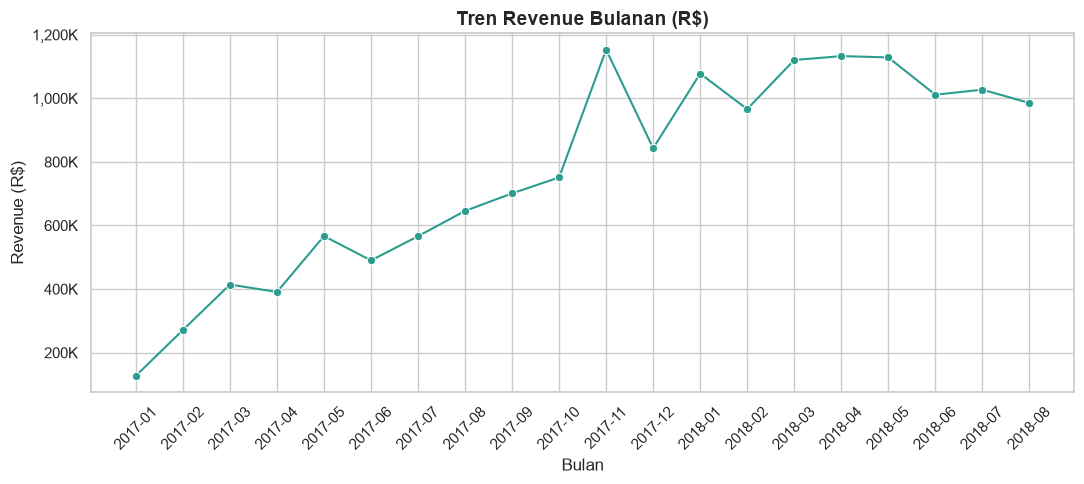

In [12]:
k_fmt = matplotlib.ticker.FuncFormatter(lambda v, _: f'{v/1e3:,.0f}K')
figs = {}

fig, ax = plt.subplots(figsize=(11, 5))
sns.lineplot(data=trend, x='order_month', y='revenue', marker='o', color='#2a9d8f', ax=ax)
ax.set_title('Tren Revenue Bulanan (R$)', fontsize=14, weight='bold')
ax.set_xlabel('Bulan'); ax.set_ylabel('Revenue (R$)'); ax.yaxis.set_major_formatter(k_fmt)
ax.tick_params(axis='x', rotation=45); fig.tight_layout()
figs['1_line_tren_revenue'] = fig
plt.show()

## 3b. BAR chart — Top 10 kategori produk

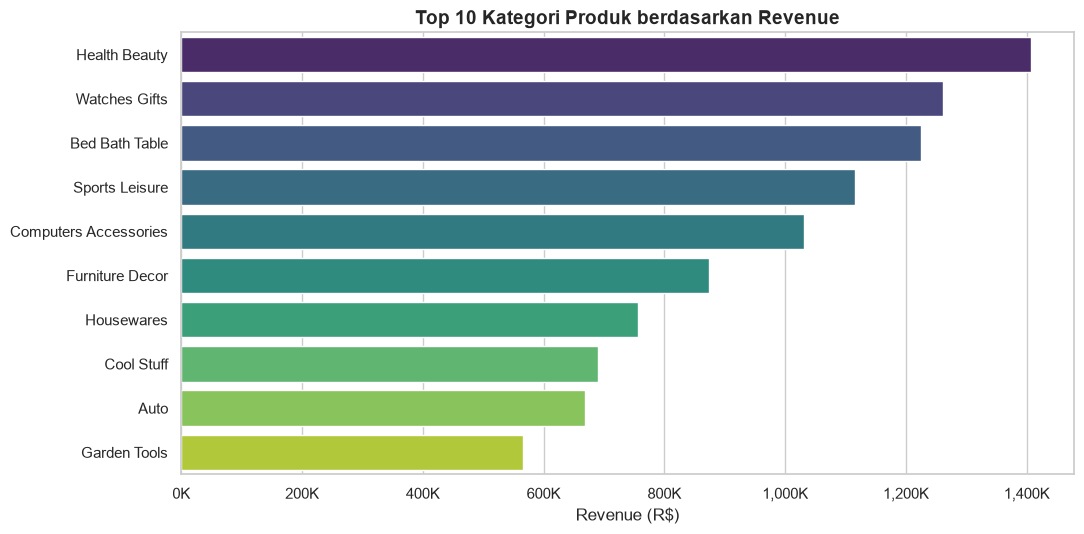

In [13]:
fig, ax = plt.subplots(figsize=(11, 5.5))
sns.barplot(data=category.head(10), y='product_category', x='revenue', hue='product_category',
            palette='viridis', legend=False, ax=ax)
ax.set_title('Top 10 Kategori Produk berdasarkan Revenue', fontsize=14, weight='bold')
ax.set_xlabel('Revenue (R$)'); ax.set_ylabel(''); ax.xaxis.set_major_formatter(k_fmt)
fig.tight_layout(); figs['2_bar_top_kategori'] = fig
plt.show()

## 3c. BAR chart — Keterlambatan vs Review Score (Business Question #2)

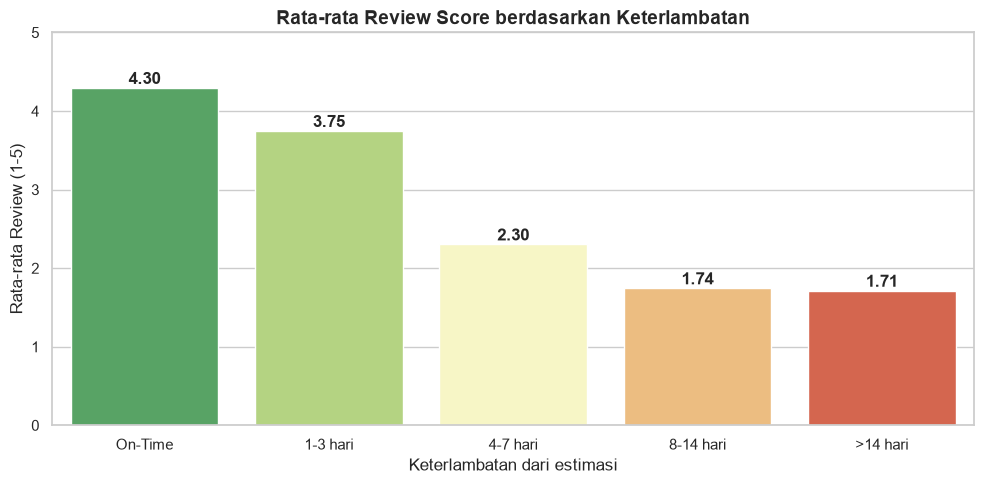

In [14]:
fig, ax = plt.subplots(figsize=(10, 5))
sns.barplot(data=delay_vs_review, x='delay_bucket', y='avg_review', hue='delay_bucket',
            palette='RdYlGn_r', legend=False, ax=ax)
for i, v in enumerate(delay_vs_review['avg_review']):
    ax.text(i, v + 0.05, f'{v:.2f}', ha='center', weight='bold')
ax.set_ylim(0, 5)
ax.set_title('Rata-rata Review Score berdasarkan Keterlambatan', fontsize=14, weight='bold')
ax.set_xlabel('Keterlambatan dari estimasi'); ax.set_ylabel('Rata-rata Review (1-5)')
fig.tight_layout(); figs['3_bar_delay_vs_review'] = fig
plt.show()

## 3d. PIE chart — Proporsi metode pembayaran

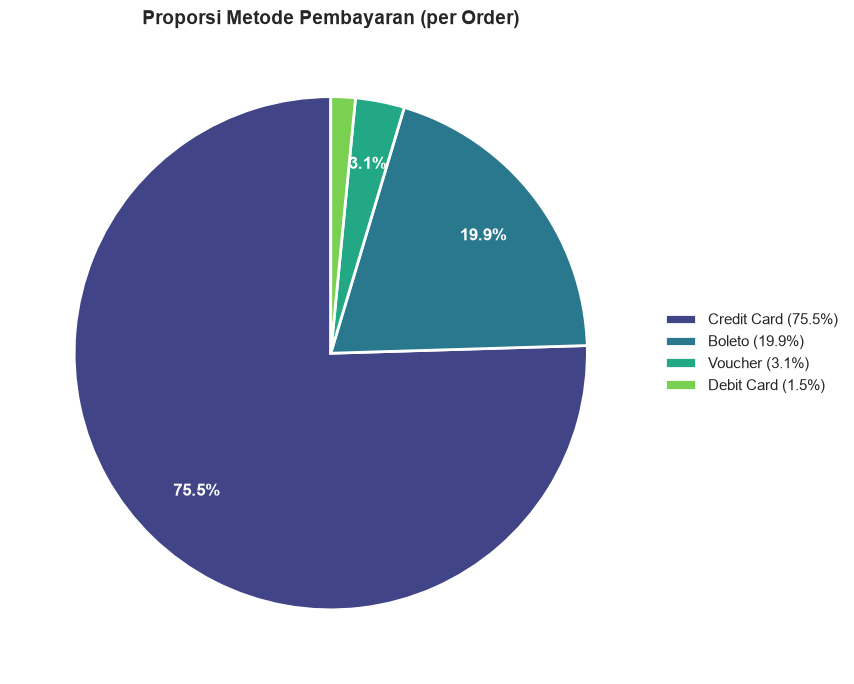

In [15]:
main = payment[payment['share_pct'] >= 1]
others = payment.loc[payment['share_pct'] < 1, 'total_order'].sum()
labels = list(main['payment_type']) + (['Lainnya'] if others else [])
values = list(main['total_order']) + ([others] if others else [])

fig, ax = plt.subplots(figsize=(9, 7))
total = sum(values)
ax.pie(values, autopct=lambda pct: f'{pct:.1f}%' if pct >= 3 else '', startangle=90, pctdistance=0.75,
       colors=sns.color_palette('viridis', len(values)),
       textprops={'color': 'white', 'weight': 'bold', 'fontsize': 12},
       wedgeprops={'edgecolor': 'white', 'linewidth': 2})
ax.legend([f'{l} ({v / total * 100:.1f}%)' for l, v in zip(labels, values)],
          loc='center left', bbox_to_anchor=(1, 0.5), frameon=False)
ax.set_title('Proporsi Metode Pembayaran (per Order)', fontsize=14, weight='bold')
fig.tight_layout(); figs['4_pie_payment'] = fig
plt.show()

---
# TAHAP 4 — OTOMATISASI LAPORAN
Satu kali jalan → otomatis menghasilkan **CSV untuk Tableau**, **laporan Excel multi-sheet**, dan **laporan PDF**.

> 💼 Untuk update harian otomatis, jalankan `run_daily_report.bat` lewat Windows Task Scheduler (langkahnya ada di `TABLEAU_GUIDE.md`).

In [16]:
run_time = datetime.now().strftime('%Y-%m-%d %H:%M')

# 4a. Simpan grafik PNG
for name, fig in figs.items():
    fig.savefig(os.path.join(OUTPUT_DIR, 'charts', f'{name}.png'), dpi=120)

# 4b. CSV master untuk Tableau
out = master.copy()
for c in ['order_purchase_timestamp', 'order_delivered_customer_date', 'order_estimated_delivery_date']:
    out[c] = out[c].dt.strftime('%Y-%m-%d %H:%M:%S')
out['order_purchase_month'] = out['order_purchase_month'].dt.strftime('%Y-%m-%d')
out.to_csv(os.path.join(OUT_ROOT, 'ecommerce_master_clean.csv'), index=False, encoding='utf-8')

# 4c. Excel multi-sheet
xlsx_path = os.path.join(OUTPUT_DIR, 'laporan_penjualan.xlsx')
with pd.ExcelWriter(xlsx_path, engine='openpyxl') as w:
    for name, sdf in {'Ringkasan KPI': kpi, 'Tren Bulanan': trend, 'Kategori Produk': category,
                      'Wilayah (State)': state, 'Delay vs Review': delay_vs_review,
                      'Metode Bayar': payment, 'Data Kosong (Raw)': missing_before,
                      'Log Cleaning': pd.DataFrame({'langkah': log})}.items():
        sdf.to_excel(w, sheet_name=name, index=False)
        for col in w.sheets[name].columns:
            width = max(len(str(c.value)) if c.value is not None else 0 for c in col)
            w.sheets[name].column_dimensions[col[0].column_letter].width = min(width + 2, 60)

# 4d. PDF: halaman ringkasan KPI + semua grafik
pdf_path = os.path.join(OUTPUT_DIR, 'laporan_penjualan.pdf')
with PdfPages(pdf_path) as pdf:
    cover, ax = plt.subplots(figsize=(11, 6)); ax.axis('off')
    ax.text(0.5, 0.92, 'Laporan Penjualan Olist E-Commerce', ha='center', fontsize=20, weight='bold')
    ax.text(0.5, 0.84, f'Periode 2017-01 s/d 2018-08  |  Dibuat: {run_time}', ha='center', color='gray')
    for i, r in kpi.iterrows():
        val = f"{r['Nilai']:,.2f}" if isinstance(r['Nilai'], float) else f"{r['Nilai']:,}"
        ax.text(0.2, 0.70 - i * 0.08, r['Metrik'], fontsize=12)
        ax.text(0.8, 0.70 - i * 0.08, val, fontsize=12, ha='right', weight='bold')
    pdf.savefig(cover); plt.close(cover)
    for fig in figs.values():
        pdf.savefig(fig)

print('✓ CSV Tableau :', os.path.join(OUT_ROOT, 'ecommerce_master_clean.csv'))
print('✓ Excel       :', xlsx_path)
print('✓ PDF         :', pdf_path)

✓ CSV Tableau : .\ecommerce_master_clean.csv
✓ Excel       : .\output\laporan_penjualan.xlsx
✓ PDF         : .\output\laporan_penjualan.pdf


---
## ✅ Kesimpulan & Langkah Berikutnya
- File `ecommerce_master_clean.csv` siap di-import ke **Tableau** untuk dashboard interaktif.
- Panduan Tableau dari nol: lihat **`TABLEAU_GUIDE.md`**.